In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import AutoMinorLocator
from matplotlib import patches
import sunpy
import sunpy.visualization
from sunpy.coordinates.spice import get_rotation_matrix
from sunpy.coordinates import propagate_with_solar_surface
from scipy.ndimage import map_coordinates
from astropy.io import fits 
from astropy.wcs import WCS
from astropy.wcs.utils import pixel_to_pixel
import astropy.constants as const
import astropy.units as u
from astropy.visualization import ImageNormalize
from ndcube import NDCube
from ndcube.wcs.tools import unwrap_wcs_to_fitswcs
import os
os.environ["SPICE_KERNEL_PATH"] = "/cluster/home/zhuyin/scripts/spice_kernel/"
from mag_reproject import hgs_local_to_heeq_cart
from copy import deepcopy
import pyvista as pv
import pandas as pd
import mhsxtrapy
from mhsxtrapy.plotting import plot_magnetogram, plot_field_3d
from tqdm.notebook import tqdm
from joblib import Parallel, delayed
from glob import glob 

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


In [2]:
dkist_vbi_target_header = fits.getheader("../../data/pid_1_123_aux/plot_ready/dkist_target_wcs_header_before_crop.fits",
                                        ignore_missing_simple=True)

# make a fake pointing 
dkist_vbi_target_header["CRVAL1"] += -80
dkist_vbi_target_header["CRVAL2"] += -10

dkist_vbi_target_data = np.zeros((4096,4096))

dkist_vbi_target_cube = NDCube(dkist_vbi_target_data,WCS(dkist_vbi_target_header, naxis=2))
dkist_vbi_target_cube_crop = dkist_vbi_target_cube[128*2:-128*2,128*2:-128*2]
dkist_vbi_target_cube_crop_rebin = dkist_vbi_target_cube_crop.rebin((8,8))

Set MJD-BEG to 59876.791095 from DATE-BEG.
Set MJD-AVG to 59876.791095 from DATE-AVG.
Set MJD-END to 59876.791095 from DATE-END'. [astropy.wcs.wcs]
Set OBSGEO-B to    20.706700 from OBSGEO-[XYZ].
Set OBSGEO-H to     3063.997 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


In [3]:
data_bz = np.load("/cluster/home/zhuyin/Solar/DKIST_SolO_Fibril/data/pid_1_123_aux/SOTSP/sotsp_bz_hgs_cea_fullfov.npy").T
data_bx = np.load("/cluster/home/zhuyin/Solar/DKIST_SolO_Fibril/data/pid_1_123_aux/SOTSP/sotsp_bx_hgs_cea_fullfov.npy").T
data_by = np.load("/cluster/home/zhuyin/Solar/DKIST_SolO_Fibril/data/pid_1_123_aux/SOTSP/sotsp_by_hgs_cea_fullfov.npy").T

In [4]:
fibril_tracing_ensemble = np.load("../../sav/fibril_tracing/fibril_mask_ensemble.npy")

In [5]:
def skeleton_orientation_pca(skel, window=5):
    """
    Compute orientation at each skeleton point using PCA on neighbors.
    Returns angles in [0, 180): 0 = vertical (top-down), 90 = horizontal, clockwise.
    """
    ys, xs = np.nonzero(skel)
    angles = np.full(skel.shape, np.nan)
    half = window // 2
    
    # Build a KD-tree-like lookup using the coordinate array
    coords = np.column_stack([ys, xs])
    
    for y, x in zip(ys, xs):
        # Get neighbors within a window
        mask = (np.abs(coords[:, 0] - y) <= half) & (np.abs(coords[:, 1] - x) <= half)
        nbrs = coords[mask]
        if len(nbrs) < 2:
            continue
        
        # PCA: principal direction = eigenvector of largest eigenvalue
        centered = nbrs - nbrs.mean(axis=0)
        cov = np.cov(centered.T)
        eigvals, eigvecs = np.linalg.eigh(cov)
        vy, vx = eigvecs[:, -1]  # largest eigenvalue's eigenvector (dy, dx)
        
        # Convert to your convention:
        # 0 = top-down (vertical), 90 = left-right (horizontal), clockwise
        # Standard math angle from +x axis: atan2(vy, vx) [note: image y is flipped]
        # We want angle from vertical, clockwise in image coords (y increases downward)
        ang = np.degrees(np.arctan2(vx, vy))   # angle from vertical axis
        ang = ang % 180                         # fold into [0, 180)
        angles[y, x] = ang
    
    return angles

In [6]:
def angle_between(skel_angle, vec_angle):
    """
    skel_angle: orientation in [0, 180), 180-ambiguous
    vec_angle: direction in [0, 360), fully directed
    Returns: angle between them in [0, 90]
    """
    diff = (vec_angle - skel_angle) % 180   # fold by 180 (skeleton symmetry)
    return np.minimum(diff, 180 - diff)     # fold by 90 (take acute angle)

In [7]:
skel_angle_list = []
skel_angle_ys_list = []
skel_angle_xs_list = []

for skel in tqdm(fibril_tracing_ensemble):
    skel_angle = skeleton_orientation_pca(skel)
    skel_angle_ys, skel_angle_xs = np.nonzero(~np.isnan(skel_angle))
    skel_angle_list.append(skel_angle)
    skel_angle_ys_list.append(skel_angle_ys)
    skel_angle_xs_list.append(skel_angle_xs)

skel_angle_list = np.asarray(skel_angle_list)

  0%|          | 0/12 [00:00<?, ?it/s]

In [8]:
# data_bz_crop = data_bz[150:150+350, 330:330+350]
data_bz_crop = data_bz

In [10]:

sotsp_br_map = sunpy.map.Map("../../data/pid_1_123_aux/SOTSP/sotsp_bz_hgs_cea_fullfov.fits")
# sotsp_br_map_crop = sotsp_br_map.submap(
#     bottom_left=(330, 150)*u.pix,
#     top_right=(330+350-1, 150+350-1)*u.pix
# )

sotsp_br_map_crop = sotsp_br_map

sotsp_br_map_crop_center_lon = -24.866559216955352 
sotsp_br_map_crop_center_lat = 16.31003568484626

sotsp_br_wcs_mod_mhs_list = []
for ii in range(0,100):
    height_ = ii*0.05e6
    sotsp_br_wcs_mod_ = deepcopy(sotsp_br_map_crop.wcs)
    sotsp_br_wcs_mod_.wcs.aux.rsun_ref = sotsp_br_wcs_mod_.wcs.aux.rsun_ref + height_
    sotsp_br_wcs_mod_mhs_list.append(sotsp_br_wcs_mod_)

In [11]:
dkist_wcs_mod_mhs_list = []
for ii in range(0,100):
    dkist_wcs_mod_ = deepcopy(dkist_vbi_target_cube_crop.wcs)
    dkist_wcs_mod_ = unwrap_wcs_to_fitswcs(dkist_wcs_mod_)[0]
    dkist_wcs_mod_.wcs.aux.rsun_ref = sotsp_br_wcs_mod_mhs_list[ii].wcs.aux.rsun_ref
    dkist_wcs_mod_mhs_list.append(dkist_wcs_mod_)

In [12]:
def draw_colorwheel(parent_ax, bbox=[0, 0, 0.22, 0.22], show_labels=True,
                    box_pad=0.01, box_facecolor='white', box_edgecolor='gray',
                    box_alpha=0.6, box_linewidth=0.8, corner_radius=0.02,
                    cmap='twilight_shifted'):
    n = 512
    theta = np.linspace(0, 2*np.pi, n)
    r = np.linspace(0., 1, n)
    T, R = np.meshgrid(theta, r)
    Z = T

    # Rounded background rectangle in parent-axes coordinates
    x0, y0, w, h = bbox
    rect = patches.FancyBboxPatch(
        (x0 - box_pad, y0 - box_pad),
        w + 2*box_pad, h + 2*box_pad,
        boxstyle=f"round,pad=0,rounding_size={corner_radius}",
        transform=parent_ax.transAxes,
        facecolor=box_facecolor, edgecolor=box_edgecolor,
        linewidth=box_linewidth, alpha=box_alpha,
        zorder=4, rasterized=True
    )
    parent_ax.add_patch(rect)

    ax = parent_ax.inset_axes(bbox, projection='polar')
    ax.set_zorder(5)

    if isinstance(cmap, str):
        cmap = plt.get_cmap(cmap)
    ax.pcolormesh(T, R, Z, cmap=cmap, shading='auto',
                  norm=ImageNormalize(vmin=0, vmax=2*np.pi),
                  edgecolors='none', linewidth=0,
                  rasterized=True)

    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    ax.grid(False)
    ax.set_yticklabels([])
    ax.set_ylim(0, 1)

    ax.spines['polar'].set_visible(False)
    ax.tick_params(which='both', length=0)
    ax.patch.set_alpha(0)

    if show_labels:
        ax.set_xticks(np.deg2rad([0, 90, 180, 270]))
        ax.set_xticklabels(['0°', '90°', '180°', '270°'], fontsize=8)
    else:
        ax.set_xticklabels([])
    
    return ax

In [13]:
def precompute_skeleton_sampling(map_wcs, dkist_wcs, xs, ys, xlim=None, ylim=None):
    """Map skeleton pixels (DKIST grid) -> input-map pixel coords, once."""
    if xlim is not None and ylim is not None:
        m = (xs >= xlim[0]) & (xs <= xlim[1]) & (ys >= ylim[0]) & (ys <= ylim[1])
        xs, ys = xs[m], ys[m]
    with propagate_with_solar_surface():
        x_in, y_in = pixel_to_pixel(dkist_wcs, map_wcs,
                                    xs.astype(float), ys.astype(float))
    return xs, ys, np.asarray(x_in), np.asarray(y_in)

In [15]:
def prepare_height_independent_work(
    dateobs=sotsp_br_map.date.isot, map_wcs=sotsp_br_wcs_mod_mhs_list[0],
    dkist_wcs=dkist_wcs_mod_mhs_list[0], 
    skel_angle_list=skel_angle_list,
    skel_angle_ys_list=skel_angle_ys_list,
    skel_angle_xs_list=skel_angle_xs_list,
    xlim=None, ylim=None
    ):
    
    skel_at_pts_list = []
    xs_list = []
    ys_list = []
    x_in_list = []
    y_in_list = []

    for skel_angle, skel_angle_ys, skel_angle_xs in zip(
        skel_angle_list, skel_angle_ys_list, skel_angle_xs_list
        ):
        # --- height-independent work, done once ---
        xs, ys, x_in, y_in = precompute_skeleton_sampling(
            map_wcs, dkist_wcs, skel_angle_xs, skel_angle_ys, xlim, ylim)
        skel_at_pts = skel_angle[ys, xs]
        skel_at_pts_list.append(skel_at_pts)
        xs_list.append(xs)
        ys_list.append(ys)
        x_in_list.append(x_in)
        y_in_list.append(y_in)
        
    R = get_rotation_matrix("SUN_EARTH_CEQU", "EARTH_SOLAR_MHP", dateobs)

    return skel_at_pts_list, R, xs_list, ys_list, x_in_list, y_in_list

In [17]:
skel_info_mhs_list = []

for ii in range(0,100):
    skel_info_mhs_ = prepare_height_independent_work(
        dateobs=sotsp_br_map.date.isot, map_wcs=sotsp_br_wcs_mod_mhs_list[ii],
        dkist_wcs=dkist_wcs_mod_mhs_list[ii], 
        skel_angle_list=skel_angle_list,
        skel_angle_ys_list=skel_angle_ys_list,
        skel_angle_xs_list=skel_angle_xs_list
    )

    skel_info_mhs_list.append(skel_info_mhs_)

In [16]:
# skel_at_pts_list, R, xs_list, ys_list, x_in_list, y_in_list = prepare_height_independent_work()

In [18]:
def _sample_bilinear(img, x_in, y_in):
    """Bilinear sampling like reproject_interp; NaN outside the input image."""
    ny, nx = img.shape
    good = (np.isfinite(x_in) & np.isfinite(y_in)
            & (x_in >= -0.5) & (x_in <= nx - 0.5)
            & (y_in >= -0.5) & (y_in <= ny - 0.5))
    out = np.full(x_in.shape, np.nan)
    out[good] = map_coordinates(img, [y_in[good], x_in[good]],
                                order=1, mode="nearest")
    return out


def half_angle_from_vals(vals, nbins=100, n_bg=10):
    counts, edges = np.histogram(vals, bins=nbins, density=True, range=(0, 90))
    reduced = np.clip(counts - np.nanmean(counts[-n_bg:]), 0, None)
    cdf = np.cumsum(reduced * np.diff(edges))
    if not np.isfinite(cdf[-1]) or cdf[-1] <= 0:
        return np.nan
    return np.interp(0.5, cdf / cdf[-1], 0.5 * (edges[:-1] + edges[1:]))


def survey_height_sep_ensemble(
    bz, alpha, a=0.05, load_path=None,
    height_indices=np.arange(0, 100, dtype=int),
    lon=sotsp_br_map_crop_center_lon, lat=sotsp_br_map_crop_center_lat,
    xlim=None, ylim=None,
    skel_info_list=skel_info_mhs_list,
    bx_extra=None, by_extra=None,
    bz_extra=None
):
    if bz_extra is None and by_extra is None and bx_extra is None:
        ny, nx = bz.shape
        sl = (slice(ny, 2 * ny), slice(nx, 2 * nx), slice(None))
        data3d = mhsxtrapy.ExtrapolationResult.load(load_path)
        by_extra = data3d.field[sl + (0,)].astype(np.float32)
        bx_extra = data3d.field[sl + (1,)].astype(np.float32)
        bz_extra = data3d.field[sl + (2,)].astype(np.float32)
        del data3d

    # # --- height-independent work, done once ---
    # xs, ys, x_in, y_in = precompute_skeleton_sampling(
    #     map_wcs, dkist_wcs, skel_angle_xs, skel_angle_ys, xlim, ylim)
    # skel_at_pts = skel_angles[ys, xs]
    # R = get_rotation_matrix("SUN_EARTH_CEQU", "EARTH_SOLAR_MHP", dateobs)

    half_angle_array = np.full((len(height_indices),12), np.nan)
    for i, h in enumerate(tqdm(height_indices)):
        skel_at_pts_list, R, xs_list, ys_list, x_in_list, y_in_list = skel_info_list[i]
        k = slice(h, h + 1)                         # keep a length-1 z axis
        bxh, byh, bzh = hgs_local_to_heeq_cart(
            bx_extra[:, :, k].transpose(1, 0, 2),
            by_extra[:, :, k].transpose(1, 0, 2),
            bz_extra[:, :, k].transpose(1, 0, 2),
            lon, lat,
        )
        b_mhp = np.stack([bxh[..., 0], byh[..., 0], bzh[..., 0]], axis=-1) @ R.T
        hpln = -b_mhp[..., 0].T                     # (ny, nx), same as Map data
        hplt = b_mhp[..., 1].T


        for j in range(12):
            pa = np.rad2deg(np.arctan2(_sample_bilinear(hpln, x_in_list[j], y_in_list[j]),
                                       _sample_bilinear(hplt, x_in_list[j], y_in_list[j]))) % 360
            vals = angle_between(skel_at_pts_list[j], pa)
            half_angle_array[i,j] = half_angle_from_vals(vals)
        # vals = angle_between(skel_at_pts, pa)
        # half_angle_array[i] = half_angle_from_vals(vals)

    return half_angle_array

In [19]:
theta_50_vs_height_0014_null_ensemble = survey_height_sep_ensemble(
    data_bz_crop, alpha=0.014,
    load_path="/cluster/home/zhuyin/Solar/DKIST_SolO_Fibril/data/pid_1_123_aux/MHSXtra_results_new/alpha_0.0140/field3d.h5"
)

  0%|          | 0/100 [00:00<?, ?it/s]

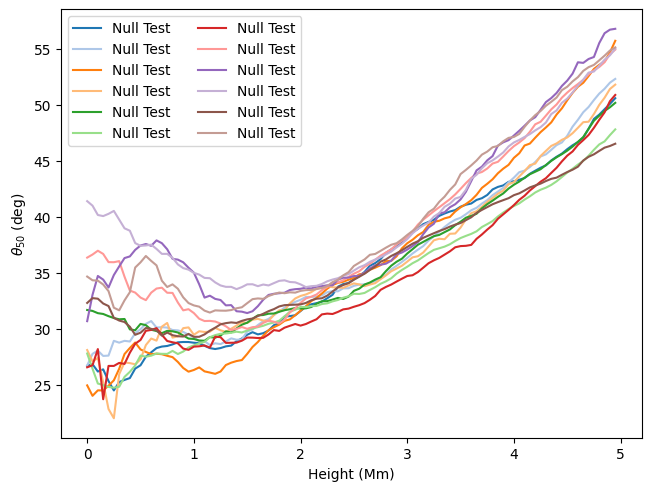

In [20]:
with plt.style.context("default"):
    fig, ax = plt.subplots(layout="constrained")
    ax.set_prop_cycle(color=plt.colormaps["tab20"].colors)
    
    for ii in range(12):
        ax.plot(
            np.arange(0, 100)*0.05, theta_50_vs_height_0014_null_ensemble[:,ii],
            label="Null Test"
        )

    
    ax.legend(loc="upper left", ncols=2)

    ax.set_xlabel("Height (Mm)")
    ax.set_ylabel(r"$\theta_{50}$ (deg)")

    plt.show()

In [18]:
np.savez(
    "/cluster/home/zhuyin/Solar/DKIST_SolO_Fibril/data/pid_1_123_aux/MHSXtra_results_new/theta_50_vs_height/theta_50_vs_height_null_ensemble.npz",
    theta_50_vs_height_0014_null_ensemble=np.asarray(theta_50_vs_height_0014_null_ensemble),
    theta_50_height_mhs=np.arange(0, 100)*0.05
)